# Phase 3b — 피처 엔지니어링 (FE) & Elliptic Envelope 재검토

지금까지 모델만 바꿔가며 비교했고, 피처(V1~V30)는 그대로 썼습니다. 이 노트북에서는 반대로 **모델은 고정하고 피처를 바꿔서** 효과를 봅니다.

Phase 3에서 "알고리즘 한계"로 기록했던 Elliptic Envelope 실패를 다시 파보다가, 데이터에 숨은 구조를 발견했습니다. 여기서 그 발견부터 직접 재현합니다.

이 노트북에서 할 일:
1. Elliptic Envelope(MCD)가 깨진 원인 재현 — 거래의 88%가 한 "평면" 위에 정확히 놓여 있다
2. Elliptic Envelope 고치기 — 평면 방향을 빼고 다시 학습
3. FE 피처 3개: 평면 이탈 거리, 시간대(hour), log 금액
4. 모델(마할라노비스, Isolation Forest 베이스라인 설정)은 고정하고 피처만 바꿔서 비교

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

train = pd.read_csv('../data/train.csv')
val = pd.read_csv('../data/val.csv')
test = pd.read_csv('../data/test.csv')
feature_cols = [c for c in train.columns if c.startswith('V')]

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

y_true = val['Class'].values

X_train = train[feature_cols].values
X_val = val[feature_cols].values
X_test = test[feature_cols].values

print('train:', train.shape, '/ val:', val.shape, '/ test:', test.shape)

train: (113842, 31) / val: (28462, 32) / test: (142503, 31)


## 공통 함수

Phase 3 보강 때 정정한 threshold 탐색(상위 k건 전수 탐색)과 macro-F1, 그리고 threshold 없이 보는 PR-AUC까지 한 번에 채점하는 함수를 준비합니다.

In [8]:
from sklearn.metrics import average_precision_score, roc_auc_score

def find_best_threshold(y_true, scores, max_k=2000):
    # 점수 상위 k건을 사기로 예측하는 모든 경우(k=1~max_k)를 빠짐없이 탐색
    order = np.argsort(-scores)
    sorted_y = y_true[order]
    n_pos = y_true.sum()
    n_neg = len(y_true) - n_pos
    k = np.arange(1, max_k + 1)
    tp = np.cumsum(sorted_y)[:max_k]
    fp = k - tp
    fn = n_pos - tp
    tn = n_neg - fp
    macro = (2 * tp / (2 * tp + fp + fn) + 2 * tn / (2 * tn + fn + fp)) / 2
    best_idx = np.argmax(macro)
    thresholds = scores[order][:max_k]
    return thresholds[best_idx], macro[best_idx], thresholds, macro

def evaluate(name, val_scores):
    # 점수(높을수록 사기)를 받아서 세 가지 지표로 채점
    _, best_f1, _, _ = find_best_threshold(y_true, val_scores)
    return {
        '모델': name,
        '최적 macro-F1': round(float(best_f1), 4),
        'PR-AUC': round(float(average_precision_score(y_true, val_scores)), 4),
        'ROC-AUC': round(float(roc_auc_score(y_true, val_scores)), 4),
    }

## 1. Elliptic Envelope가 깨진 원인 재현

**가설 ("exact fit" 상황):** MCD는 "데이터의 절반 이상을 포함하면서 공분산 행렬식(determinant)이 가장 작은 부분집합"을 찾습니다.
행렬식은 데이터가 퍼진 "부피"라고 생각하면 됩니다. 만약 데이터의 절반 이상이 어떤 **평면 위에 정확히** 놓여 있다면, 그 점들만 골랐을 때
평면에 수직인 방향으로는 두께가 0이라 부피(행렬식)도 0이 됩니다. 알고리즘 입장에서는 이게 "최적의 답"이라 그쪽으로 끌려가고,
그 결과 공분산이 특이행렬이 되어 역행렬이 폭발한 것입니다.

V1~V28은 원본 변수들을 PCA로 **선형 변환**한 값이라, 원본에 대부분의 거래에서 값이 같은 변수(예: 어떤 플래그가 0)가 있었다면
그런 평면이 생길 수 있습니다.

먼저 MCD를 학습하고, MCD가 고른 부분집합의 공분산에서 **분산(고유값)이 0에 가까운 방향**이 있는지 확인합니다. (1분 정도 걸립니다)

In [9]:
from sklearn.covariance import MinCovDet

# MCD 학습. 행렬식 관련 경고가 잔뜩 나오는데, 바로 그 원인을 이 섹션에서 확인하므로 여기선 숨깁니다
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    mcd = MinCovDet(random_state=42).fit(X_train)

support = mcd.support_   # MCD가 고른 부분집합 (True/False)
print('MCD가 고른 부분집합:', support.sum(), '/', len(X_train))

# 그 부분집합만의 공분산을 구하고, 고유값(각 방향으로의 분산)을 작은 순으로 확인
eigvals, eigvecs = np.linalg.eigh(np.cov(X_train[support], rowvar=False))
print('작은 고유값 4개:', eigvals[:4])

MCD가 고른 부분집합: 61292 / 113842
작은 고유값 4개: [-5.06857111e-17  1.66459150e-16  1.68587437e-07  6.06814904e-06]


## 2. 분산이 0인 방향 = "평면"과, 각 거래가 평면에서 벗어난 거리

고유값이 1e-16 수준이면 계산 오차 수준, 즉 사실상 0입니다. 이런 방향들로 데이터를 투영하면 부분집합의 점들은 전부 같은 값에 모여 있고,
그 값에서 얼마나 떨어져 있는지가 곧 **평면에서 벗어난 거리**입니다.

기준(tol)을 1e-10부터 1e-3까지 바꿔가며 "평면 위" 비율을 세어봅니다. 비율이 거의 안 변하면, 거래들이 "정확히 평면 위" 아니면
"확실히 평면 밖"으로 깔끔하게 갈린다는 뜻입니다.

In [10]:
n_zero = int((eigvals < 1e-10).sum())   # 분산이 사실상 0인 방향 개수
W = eigvecs[:, :n_zero]                  # 그 방향들 (30 x n_zero 행렬)
print('분산이 0인 방향 개수:', n_zero)

# 각 방향이 어떤 V 변수들의 조합인지 (가중치 절댓값 큰 순 5개)
for j in range(n_zero):
    top = np.argsort(-np.abs(W[:, j]))[:5]
    print(f'방향 {j + 1}:', ', '.join(f'{feature_cols[i]}({W[i, j]:+.2f})' for i in top))

# 평면의 위치 = 부분집합을 그 방향들로 투영했을 때의 평균
plane_center = (X_train[support] @ W).mean(axis=0)

def off_plane_distance(X):
    # 각 거래를 분산 0인 방향들로 투영한 뒤, 평면 위치에서 얼마나 떨어졌는지(유클리드 거리)
    return np.linalg.norm(X @ W - plane_center, axis=1)

dist_train = off_plane_distance(X_train)
dist_val = off_plane_distance(X_val)
dist_test = off_plane_distance(X_test)

print()
for tol in [1e-10, 1e-8, 1e-6, 1e-3]:
    print(f'평면과의 거리 < {tol:g} 인 train 거래 비율: {np.mean(dist_train < tol) * 100:.2f}%')
print(f'test 평면 위 비율 (거리 < 1e-6): {np.mean(dist_test < 1e-6) * 100:.2f}%')

분산이 0인 방향 개수: 2
방향 1: V12(-0.61), V13(+0.42), V14(+0.40), V9(+0.33), V17(+0.23)
방향 2: V17(+0.51), V7(+0.34), V10(+0.32), V12(+0.31), V16(+0.27)

평면과의 거리 < 1e-10 인 train 거래 비율: 85.87%
평면과의 거리 < 1e-08 인 train 거래 비율: 88.38%
평면과의 거리 < 1e-06 인 train 거래 비율: 88.38%
평면과의 거리 < 0.001 인 train 거래 비율: 88.38%
test 평면 위 비율 (거리 < 1e-6): 88.35%


## 3. 정상 vs 사기: 평면 위에 있는 비율이 다를까?

val은 정답이 있으니, 정상 거래와 사기 거래가 각각 몇 %나 평면 위에 있는지 비교합니다.
평면은 train만으로(MCD, 정답 없이) 찾았고 val 정답은 여기서 채점에만 쓰므로, 라벨 누수 없는 비지도 FE입니다.

In [11]:
on_plane_val = dist_val < 1e-6

table = pd.DataFrame({
    '평면 위': [on_plane_val[y_true == 0].sum(), on_plane_val[y_true == 1].sum()],
    '평면 밖': [(~on_plane_val)[y_true == 0].sum(), (~on_plane_val)[y_true == 1].sum()],
}, index=['정상(0)', '사기(1)'])
table['평면 밖 비율(%)'] = (table['평면 밖'] / (table['평면 위'] + table['평면 밖']) * 100).round(2)
display(table)

# 사기가 정상과 같은 비율로 평면 밖에 있다면, 30건 중 몇 건이 평면 밖일 거라고 기대되는지
expected = 30 * (~on_plane_val)[y_true == 0].mean()
print(f'사기가 정상과 같은 비율이었다면 평면 밖 사기 기대값: {expected:.1f}건 / 실제: {(~on_plane_val)[y_true == 1].sum()}건')

print(f'\n평면 이탈 거리를 그대로 점수로 썼을 때: {evaluate("평면 이탈 거리", dist_val)}')
print('(참고: IF 베이스라인 설정 PR-AUC 0.3938, 마할라노비스 0.3161)')

,평면 위,평면 밖,평면 밖 비율(%)
정상(0),25111,3321,11.68
사기(1),5,25,83.33


사기가 정상과 같은 비율이었다면 평면 밖 사기 기대값: 3.5건 / 실제: 25건

평면 이탈 거리를 그대로 점수로 썼을 때: {'모델': '평면 이탈 거리', '최적 macro-F1': 0.8332, 'PR-AUC': 0.6773, 'ROC-AUC': 0.925}
(참고: IF 베이스라인 설정 PR-AUC 0.3938, 마할라노비스 0.3161)


## 4. 시각화

왼쪽: 정상과 사기가 각각 평면 위/밖에 몇 %씩 있는지.
오른쪽: 평면 **밖** 거래들만 골라서, 얼마나 멀리 벗어났는지의 분포. 평면 밖 정상 거래도 3천 건이 넘으니,
"평면 밖이냐"만으로는 부족하고 "얼마나 멀리 벗어났냐"가 사기를 가르는지 봅니다. 거리 범위가 넓어서 로그 스케일로 그립니다.

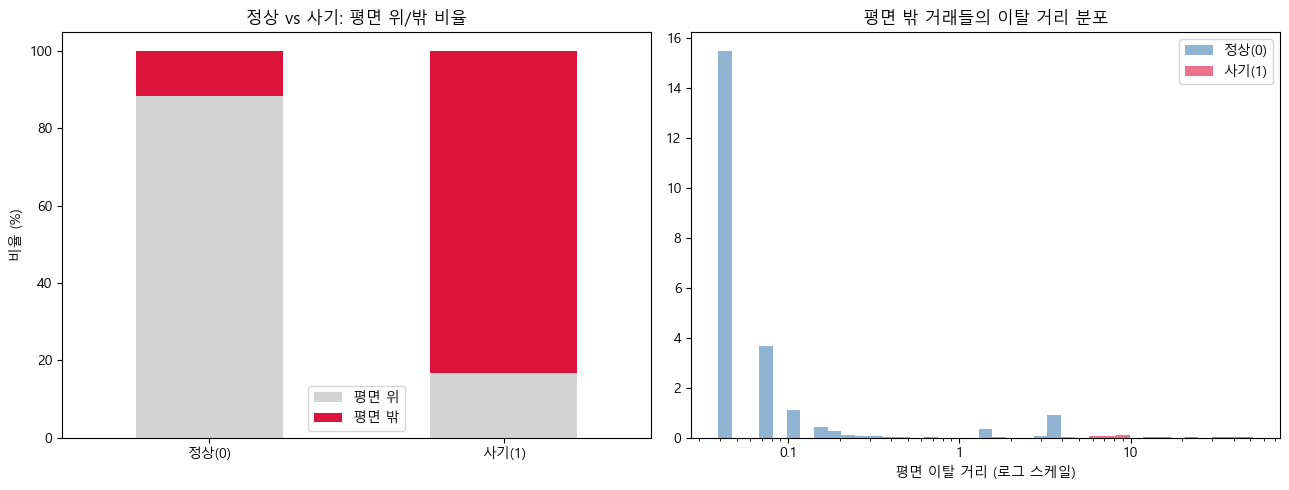

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 왼쪽: 클래스별 평면 위/밖 비율 (100% 누적 막대)
ratio = table[['평면 위', '평면 밖']].div(table[['평면 위', '평면 밖']].sum(axis=1), axis=0) * 100
ratio.plot(kind='bar', stacked=True, ax=axes[0], color=['lightgray', 'crimson'])
axes[0].set_ylabel('비율 (%)')
axes[0].set_title('정상 vs 사기: 평면 위/밖 비율')
axes[0].tick_params(axis='x', rotation=0)

# 오른쪽: 평면 밖 거래들의 이탈 거리 분포 (로그 스케일 구간)
off = ~on_plane_val
bins = np.logspace(np.log10(dist_val[off].min()), np.log10(dist_val[off].max()), 40)
axes[1].hist(dist_val[off & (y_true == 0)], bins=bins, density=True, alpha=0.6, color='steelblue', label='정상(0)')
axes[1].hist(dist_val[off & (y_true == 1)], bins=bins, density=True, alpha=0.6, color='crimson', label='사기(1)')
axes[1].set_xscale('log')
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))  # 눈금을 0.01, 0.1, 1 처럼 일반 숫자로 표시
axes[1].set_xlabel('평면 이탈 거리 (로그 스케일)')
axes[1].set_title('평면 밖 거래들의 이탈 거리 분포')
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Elliptic Envelope 고치기: 평면 방향을 빼면 될까?

아이디어: 분산이 0인 방향 때문에 공분산이 특이행렬이 됐으니, 그 방향들을 빼고 남은 "평면 안쪽" 좌표에서만 학습하면 됩니다.

그런데 1층 방향 2개를 빼고 다시 MCD를 돌려보면 **또 분산 0인 방향이 나옵니다** (평면 안에 또 평면이 있는 양파 구조).
그래서 "MCD 돌리기 → 분산 0 방향 찾기 → 빼기"를 분산 0 방향이 더 안 나올 때까지 반복합니다.
1층은 앞에서 이미 찾았으니 재사용하고, 2층부터 MCD를 새로 돌립니다 (MCD를 두 번 더 돌려서 2~3분 걸립니다).

In [13]:
# 1층: 앞에서 찾은 분산 0 방향 n_zero개를 빼고, 나머지(평면 '안쪽' 방향들)만 남김
B = eigvecs[:, n_zero:]   # 30 x 28 행렬: 각 열이 남은 방향 하나
layer_info = [{'층': 1, '남은 차원': 30, '분산 0 방향 수': n_zero,
               'train 평면 위(%)': round(np.mean(dist_train < 1e-6) * 100, 1)}]

# 2층부터: 남은 좌표로 MCD를 다시 돌려서, 분산 0 방향이 또 있으면 빼기를 반복
for layer in range(2, 6):
    X_proj = X_train @ B   # 남은 방향들로 좌표 변환
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        sub = MinCovDet(random_state=42).fit(X_proj).support_
    ev, evec = np.linalg.eigh(np.cov(X_proj[sub], rowvar=False))
    nz = int((ev < 1e-10).sum())
    if nz == 0:
        print(f'{layer}층: 남은 {B.shape[1]}차원에는 분산 0인 방향이 없음 -> 벗기기 끝 (가장 작은 분산 {ev[0]:.1e})')
        break
    W_layer = B @ evec[:, :nz]   # 이번 층의 분산 0 방향을 원래 30차원 좌표로 표현
    center_layer = (X_train[sub] @ W_layer).mean(axis=0)
    on_layer = np.linalg.norm(X_train @ W_layer - center_layer, axis=1) < 1e-6
    layer_info.append({'층': layer, '남은 차원': B.shape[1], '분산 0 방향 수': nz,
                       'train 평면 위(%)': round(on_layer.mean() * 100, 1)})
    B = B @ evec[:, nz:]   # 이번 층 방향도 빼고 나머지만 남김

display(pd.DataFrame(layer_info))
print('최종 남은 차원:', B.shape[1])

3층: 남은 24차원에는 분산 0인 방향이 없음 -> 벗기기 끝 (가장 작은 분산 6.3e-07)


,층,남은 차원,분산 0 방향 수,train 평면 위(%)
0,1,30,2,88.4
1,2,28,4,62.4


최종 남은 차원: 24


## 6. 남은 차원에서 Elliptic Envelope 재학습 및 비교

평면 방향을 다 뺀 좌표에서 Elliptic Envelope를 다시 학습하고, 이번엔 공분산이 정상인지(조건수) 확인합니다.
그리고 네 가지를 같은 기준으로 비교합니다.
- 고친 Elliptic Envelope (남은 차원)
- 같은 남은 차원에서의 일반 마할라노비스 → "강건한 추정"의 효과만 따로 보기
- 원래 30차원 마할라노비스 (Phase 2) → "평면 방향을 뺀 대가" 보기
- 평면 이탈 거리 (1층) → 뺀 방향에 담겨 있던 정보

In [14]:
from sklearn.covariance import EllipticEnvelope

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    ee_fixed = EllipticEnvelope(contamination=0.001, random_state=42).fit(X_train @ B)
n_warn = sum('Determinant has increased' in str(w.message) for w in caught)

print(f'MCD 경고 개수: {n_warn}')
print(f'공분산 조건수: {np.linalg.cond(ee_fixed.covariance_):.2e}  (Phase 3 원래 버전: 1e16~1e17)')
ee_fixed_scores_val = -ee_fixed.decision_function(X_val @ B)
print(f'val 점수 범위: {ee_fixed_scores_val.min():.3g} ~ {ee_fixed_scores_val.max():.3g}')

def mahalanobis_scores(X_fit, X_score):
    # X_fit의 평균·공분산을 기준으로 X_score 각 행의 마할라노비스 거리
    mu = X_fit.mean(axis=0)
    cov_inv = np.linalg.inv(np.cov(X_fit, rowvar=False))
    d = X_score - mu
    return np.sqrt(np.sum((d @ cov_inv) * d, axis=1))

ee_comparison = pd.DataFrame([
    evaluate(f'Elliptic Envelope (평면 방향 제거, {B.shape[1]}차원)', ee_fixed_scores_val),
    evaluate(f'마할라노비스 (같은 {B.shape[1]}차원)', mahalanobis_scores(X_train @ B, X_val @ B)),
    evaluate('마할라노비스 (원래 30차원)', mahalanobis_scores(X_train, X_val)),
    evaluate('평면 이탈 거리 (1층)', dist_val),
])
display(ee_comparison)

MCD 경고 개수: 153
공분산 조건수: 1.76e+07  (Phase 3 원래 버전: 1e16~1e17)
val 점수 범위: -3.57e+08 ~ 1.5e+09


,모델,최적 macro-F1,PR-AUC,ROC-AUC
0,"Elliptic Envelope (평면 방향 제거, 24차원)",0.6695,0.1793,0.8437
1,마할라노비스 (같은 24차원),0.6488,0.1170,0.9412
2,마할라노비스 (원래 30차원),0.7324,0.3161,0.9466
3,평면 이탈 거리 (1층),0.8332,0.6773,0.9250


## 7. FE 피처 만들기

V29, V30은 원본 `Amount`(금액), `Time`(첫 거래 이후 경과 초)에 RobustScaler(중앙값을 빼고 IQR로 나눔)를 적용한 값이라,
원본 데이터셋의 중앙값·IQR로 거꾸로 계산하면 원래 값으로 정확히 되돌릴 수 있습니다 (금액은 센트 단위, 시간은 초 단위 정수로 복원됨).

만들 피처:
- **log 금액** = log(금액 + 1): 금액은 오른쪽 꼬리가 매우 길어서(V29 왜도 11.8) 공분산이 극단값에 휘둘립니다. 로그로 눌러줍니다.
- **시간대 sin/cos**: 시각(0~23시)을 그냥 숫자로 쓰면 23시와 0시가 23만큼 떨어져 보입니다. 시계처럼 원 위의 점(sin, cos)으로 바꾸면
  23시와 0시가 가까워집니다. (실제 시각은 모르고 "데이터 시작 시점 기준" 시각입니다)
- **평면 이탈 거리**: 섹션 2에서 만든 값 (train으로만 찾은 평면 기준)

In [15]:
def add_features(df, off_dist):
    out = df[feature_cols].copy()
    amount = df['V29'] * 71.565 + 22.0     # 금액 = V29 × IQR + 중앙값
    seconds = df['V30'] * 85119 + 84692     # 경과 시간(초) = V30 × IQR + 중앙값
    hour = (seconds // 3600) % 24           # 0~23시 (데이터 시작 시점 기준)

    out['log_amount'] = np.log1p(amount)                # log(금액 + 1)
    out['hour_sin'] = np.sin(2 * np.pi * hour / 24)     # 시각을 원 위의 점으로
    out['hour_cos'] = np.cos(2 * np.pi * hour / 24)
    out['off_plane_dist'] = off_dist
    out['hour'] = hour                                  # 시각화용 (모델에는 sin/cos만 씀)
    return out

train_fe = add_features(train, dist_train)
val_fe = add_features(val, dist_val)
test_fe = add_features(test, dist_test)

display(train_fe[['V29', 'log_amount', 'V30', 'hour', 'hour_sin', 'hour_cos', 'off_plane_dist']].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
V29,113842.0,0.927,3.413,-0.307,-0.231,-0.001,0.769,180.101
log_amount,113842.0,3.149,1.658,0.000,1.872,3.133,4.357,9.466
V30,113842.0,0.116,0.558,-0.995,-0.360,-0.003,0.641,1.035
hour,113842.0,14.044,5.837,0.000,10.000,15.000,19.000,23.000
hour_sin,113842.0,-0.245,0.650,-1.000,-0.866,-0.500,0.259,1.000
hour_cos,113842.0,-0.175,0.698,-1.000,-0.866,-0.259,0.500,1.000
off_plane_dist,113842.0,0.342,1.319,0.000,0.000,0.000,0.000,66.315


### 변환 전/후 비교

왼쪽 두 개: 금액 변수의 로그 변환 전/후 분포 (왜도가 얼마나 줄었는지).
오른쪽: val에서 시간대별 사기 비율. V30(선형 시간)으로는 안 보이던 "새벽에 사기가 몰린다"는 패턴이 시간대로 바꾸면 드러나는지 확인합니다.

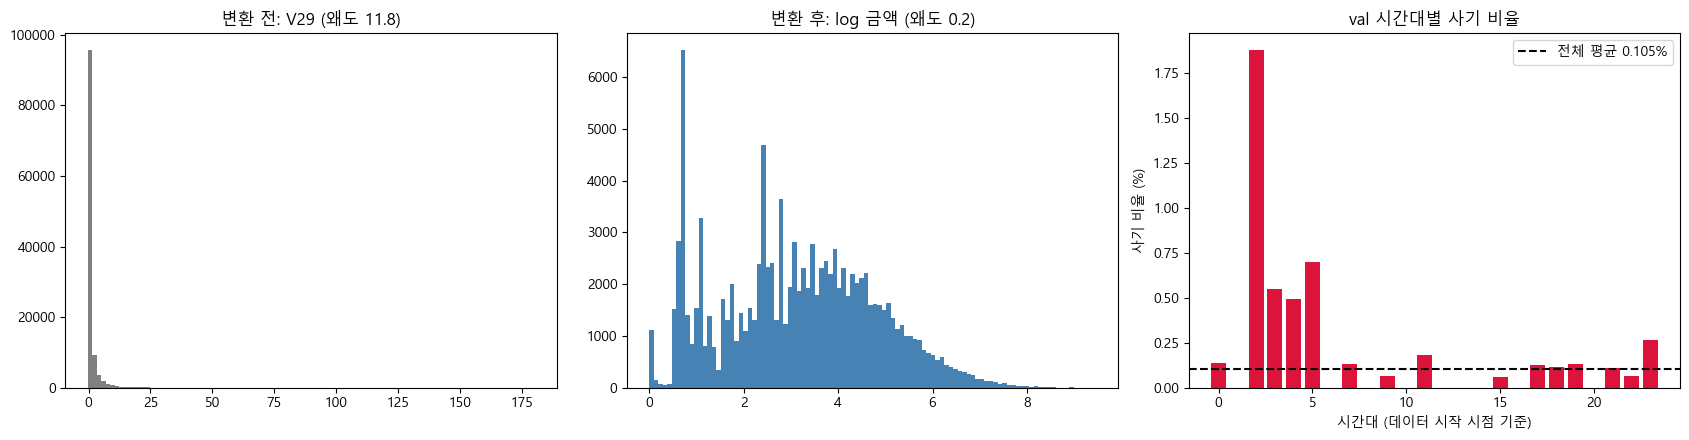

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].hist(train_fe['V29'], bins=100, color='gray')
axes[0].set_title(f"변환 전: V29 (왜도 {train_fe['V29'].skew():.1f})")

axes[1].hist(train_fe['log_amount'], bins=100, color='steelblue')
axes[1].set_title(f"변환 후: log 금액 (왜도 {train_fe['log_amount'].skew():.1f})")

hourly = val_fe.assign(Class=y_true).groupby('hour')['Class'].mean() * 100
axes[2].bar(hourly.index, hourly.values, color='crimson')
axes[2].axhline(y_true.mean() * 100, color='black', linestyle='--', label=f'전체 평균 {y_true.mean() * 100:.3f}%')
axes[2].set_xlabel('시간대 (데이터 시작 시점 기준)')
axes[2].set_ylabel('사기 비율 (%)')
axes[2].set_title('val 시간대별 사기 비율')
axes[2].legend()

plt.tight_layout()
plt.show()

## 8. 모델은 고정, 피처만 바꿔서 비교

모델 두 개(마할라노비스, Isolation Forest 베이스라인 설정)는 그대로 두고, 피처 세트만 바꿉니다. 한 번에 하나씩 바꿔야 무엇 덕분인지 알 수 있습니다.

| 세트 | 피처 | 비교 포인트 |
|---|---|---|
| A | 원본 V1~V30 | 기준 |
| B | A + 평면 이탈 거리 | 평면 이탈 거리의 효과 |
| C | V1~V28 + log 금액 + 시간대 sin/cos | 금액·시간 변환의 효과 |
| D | C + 평면 이탈 거리 | 전부 |

지표는 세 가지를 같이 봅니다.
- **최적 macro-F1**: val 정답으로 고른 threshold (낙관적, 리더보드에서 떨어짐)
- **contamination macro-F1**: val 정답을 안 보고 "train 점수 상위 0.1055%"로 정한 threshold (두 번째 제출에서 리더보드와 더 가까웠던 방식)
- **PR-AUC**: threshold와 무관한 순위 능력

Isolation Forest를 4번 학습해서 3~5분 걸릴 수 있습니다.

In [17]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import f1_score

V_BASE = [f'V{i}' for i in range(1, 29)]   # PCA 성분 V1~V28
feature_sets = {
    'A. 원본 V1~V30': feature_cols,
    'B. A + 평면 이탈 거리': feature_cols + ['off_plane_dist'],
    'C. 금액·시간 변환': V_BASE + ['log_amount', 'hour_sin', 'hour_cos'],
    'D. C + 평면 이탈 거리': V_BASE + ['log_amount', 'hour_sin', 'hour_cos', 'off_plane_dist'],
}

val_contamination = (y_true == 1).sum() / (y_true == 0).sum()   # 베이스라인과 같은 가정 (약 0.1055%)

def contamination_f1(train_scores, val_scores):
    # train 점수의 상위 contamination 비율 지점을 threshold로 (val 정답을 안 봄)
    threshold = np.quantile(train_scores, 1 - val_contamination)
    pred = (val_scores >= threshold).astype(int)
    return round(float(f1_score(y_true, pred, average='macro')), 4), int(pred.sum())

rows = []
for set_name, cols in feature_sets.items():
    X_tr, X_va = train_fe[cols].values, val_fe[cols].values

    # 모델 1: 마할라노비스 (train 평균·공분산 기준)
    maha_tr = mahalanobis_scores(X_tr, X_tr)
    maha_va = mahalanobis_scores(X_tr, X_va)

    # 모델 2: Isolation Forest (Dacon 베이스라인 설정: 나무 125그루, 나무마다 train 전체 사용)
    iso = IsolationForest(n_estimators=125, max_samples=len(X_tr), random_state=42, n_jobs=-1).fit(X_tr)
    iso_tr = -iso.score_samples(X_tr)
    iso_va = -iso.score_samples(X_va)

    for model_name, s_tr, s_va in [('마할라노비스', maha_tr, maha_va), ('Isolation Forest', iso_tr, iso_va)]:
        row = evaluate(model_name, s_va)
        row['피처 세트'] = set_name
        row['contamination macro-F1'], row['contamination 예측 건수'] = contamination_f1(s_tr, s_va)
        rows.append(row)
    print('완료:', set_name)

fe_results = pd.DataFrame(rows)[['모델', '피처 세트', '최적 macro-F1', 'contamination macro-F1',
                                 'contamination 예측 건수', 'PR-AUC', 'ROC-AUC']]
display(fe_results)

완료: A. 원본 V1~V30
완료: B. A + 평면 이탈 거리
완료: C. 금액·시간 변환
완료: D. C + 평면 이탈 거리


,모델,피처 세트,최적 macro-F1,contamination macro-F1,contamination 예측 건수,PR-AUC,ROC-AUC
0,마할라노비스,A. 원본 V1~V30,0.7324,0.6742,33,0.3161,0.9466
1,Isolation Forest,A. 원본 V1~V30,0.7379,0.7031,29,0.3938,0.9619
2,마할라노비스,B. A + 평면 이탈 거리,0.7690,0.7331,30,0.4651,0.9483
3,Isolation Forest,B. A + 평면 이탈 거리,0.7379,0.7066,28,0.4320,0.9491
4,마할라노비스,C. 금액·시간 변환,0.7389,0.6800,31,0.3242,0.9580
5,Isolation Forest,C. 금액·시간 변환,0.7437,0.7128,31,0.4388,0.9607
6,마할라노비스,D. C + 평면 이탈 거리,0.7798,0.7341,34,0.4608,0.9595
7,Isolation Forest,D. C + 평면 이탈 거리,0.7498,0.7255,32,0.4831,0.9605


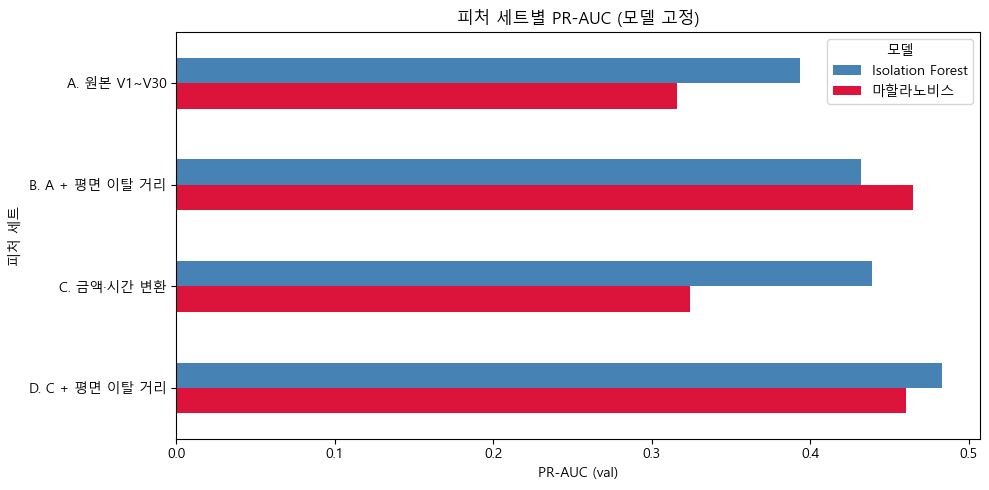

In [18]:
# 피처 세트별 PR-AUC를 모델마다 나란히 비교
pivot = fe_results.pivot(index='피처 세트', columns='모델', values='PR-AUC').loc[list(feature_sets)]
ax = pivot.plot(kind='barh', figsize=(10, 5), color=['steelblue', 'crimson'])
ax.invert_yaxis()   # A가 위로 오게
ax.set_xlabel('PR-AUC (val)')
ax.set_title('피처 세트별 PR-AUC (모델 고정)')
plt.tight_layout()
plt.show()

## 9. 점수 결합: 평면 이탈 거리 + 모델 점수 (순위 평균)

섹션 8에서 평면 이탈 거리를 모델에 **피처로 넣었더니** 효과가 희석됐습니다 (단독 PR-AUC 0.68 → 모델에 넣으면 최고 0.48).
이번엔 피처로 섞지 않고, 거리 점수와 모델 점수를 **따로 계산해서 결과만 합칩니다.**

합치는 방법: **순위 평균 (rank averaging)**
- 점수마다 단위가 다르니(거리는 0~66, IF는 0.3~0.8 등) 그대로 더할 수 없습니다. 각 점수를 "train 거래 중 몇 %보다 높은가"(백분위, 0~1)로 바꾼 뒤 평균냅니다.
- 기준을 **train**으로 잡아서 val 정답을 전혀 안 보고 train/val/test를 같은 눈금으로 바꿉니다. 그래서 contamination threshold도 그대로 쓸 수 있습니다.
- 가중치 없이 단순 평균만 하므로 val에 맞춰 튜닝할 것이 없습니다 (val 과적합 방지).
- 평면 이탈 거리는 train의 88%가 정확히 0이라 동점이 매우 많습니다. 동점은 표준적인 방식(평균 순위)으로 처리합니다.

모델 점수는 세트 C(평면 이탈 거리 미포함)와 D(포함) 두 가지로 해봅니다. D는 거리 신호를 한 번 더 세는 셈인데, 그게 도움이 되는지도 봅니다.
test 점수도 같이 계산해둡니다 (다음 제출 단계에서 사용). Isolation Forest를 2번 학습해서 2~3분 걸립니다.

In [ ]:
def train_percentile(train_scores, scores):
    # train 점수 분포 기준으로 scores가 몇 % 위치인지 (0~1). 동점은 평균 순위로 처리
    ref = np.sort(train_scores)
    below = np.searchsorted(ref, scores, side='left')          # 나보다 작은 train 점수 개수
    below_or_equal = np.searchsorted(ref, scores, side='right')  # 나보다 작거나 같은 train 점수 개수
    return (below + below_or_equal) / 2 / len(ref)

# 결합에 쓸 점수들: (train, val, test) 세 가지를 모두 계산해서 보관
component_scores = {'평면 이탈 거리': (dist_train, dist_val, dist_test)}
for set_name in ['C. 금액·시간 변환', 'D. C + 평면 이탈 거리']:
    cols = feature_sets[set_name]
    tag = set_name[0]   # 'C' 또는 'D'
    X_tr, X_va, X_te = train_fe[cols].values, val_fe[cols].values, test_fe[cols].values

    component_scores[f'마할라노비스 {tag}'] = tuple(mahalanobis_scores(X_tr, X) for X in (X_tr, X_va, X_te))

    iso = IsolationForest(n_estimators=125, max_samples=len(X_tr), random_state=42, n_jobs=-1).fit(X_tr)
    component_scores[f'IF {tag}'] = tuple(-iso.score_samples(X) for X in (X_tr, X_va, X_te))
    print('완료:', set_name)

# 모든 점수를 train 기준 백분위로 변환
pct = {name: tuple(train_percentile(s[0], x) for x in s) for name, s in component_scores.items()}

def combine(names):
    # 여러 점수의 백분위를 단순 평균 (train, val, test 각각)
    return tuple(np.mean([pct[n][i] for n in names], axis=0) for i in range(3))

combos = {
    '평면 이탈 거리 단독': ['평면 이탈 거리'],
    '거리 + 마할라노비스 C': ['평면 이탈 거리', '마할라노비스 C'],
    '거리 + 마할라노비스 D': ['평면 이탈 거리', '마할라노비스 D'],
    '거리 + IF C': ['평면 이탈 거리', 'IF C'],
    '거리 + IF D': ['평면 이탈 거리', 'IF D'],
    '거리 + 마할라노비스 C + IF C': ['평면 이탈 거리', '마할라노비스 C', 'IF C'],
    '거리 + 마할라노비스 D + IF D': ['평면 이탈 거리', '마할라노비스 D', 'IF D'],
}
combo_scores = {name: combine(parts) for name, parts in combos.items()}

rows = []
for name, (s_tr, s_va, s_te) in combo_scores.items():
    row = evaluate(name, s_va)
    row['contamination macro-F1'], row['contamination 예측 건수'] = contamination_f1(s_tr, s_va)
    rows.append(row)
combo_results = pd.DataFrame(rows)
display(combo_results)

### 사기 거래는 두 점수 공간의 어디에 있을까?

가로축은 IF D 점수의 백분위(오른쪽일수록 이상), 세로축은 평면 이탈 거리(0이면 평면 위)입니다.
- 위쪽(평면 밖, 멀리 벗어남)에 있는 사기는 거리만으로 잡힙니다.
- **맨 아래 줄(거리 0 = 평면 위)에 있는 사기**는 거리로는 절대 못 잡고, 모델 점수(가로축)로만 구분할 수 있습니다.

In [ ]:
x_pct = pct['IF D'][1]      # val의 IF D 백분위
y_dist = np.log1p(dist_val)   # 평면 이탈 거리 (로그로 눌러서 보기)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x_pct[y_true == 0], y_dist[y_true == 0], s=3, alpha=0.2, color='gray', label='정상(0)')
ax.scatter(x_pct[y_true == 1], y_dist[y_true == 1], s=45, color='crimson', edgecolor='black', label='사기(1)')
ax.set_xlabel('IF D 점수의 train 기준 백분위 (오른쪽일수록 이상)')
ax.set_ylabel('log(1 + 평면 이탈 거리)   (0 = 평면 위)')
ax.set_title('val: 두 점수로 본 정상/사기 거래의 위치')
ax.legend()
plt.show()

on_plane_fraud = (dist_val < 1e-6) & (y_true == 1)
print('평면 위에 있는 사기의 IF D 백분위:', np.round(np.sort(x_pct[on_plane_fraud]), 4))